# **Descripción breve del caso**

CoffeeTime Café es una cadena ficticia de cafeterías que cuenta con diferentes locales y ofrece una variedad de productos, desde cafés tradicionales hasta bebidas especializadas. Durante los últimos meses, la empresa ha experimentado variaciones en el comportamiento de consumo de sus clientes, diferencias en el ticket promedio entre locales y cambios en la frecuencia de visitas.

El objetivo de este proyecto es comprender mejor los patrones de consumo utilizando Machine Learning y Data Science para que la gerencia esté feliz y te den un ascenso _:)_

# **Elección de Modelos**

## **Carga de Librerías**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor

## **Lectura del dataset**

In [3]:
df = pd.read_csv('coffee_sales_clean.csv')
display(df.head())
print(df.info())

,customer_id,age,visit_frequency,coffee_type_preferred,time_of_visit,satisfaction_score,total_monthly_spent,store_location,membership_tier,promo_used,avg_wait_time_min,days_since_last_visit,avg_spent,return_next_week
0,CUST_0001,56,3.2,Espresso,Manana,1,262.53,Mall,Silver,0,6.5,6,20.51,0
1,CUST_0002,46,2.7,Cappuccino,Tarde,5,210.28,Residencial,Regular,0,12.8,10,19.47,1
2,CUST_0003,32,2.3,Cappuccino,Tarde,3,181.98,Centro,Regular,1,9.0,10,19.78,0
3,CUST_0004,60,3.2,Latte,Tarde,3,344.32,Mall,Regular,0,8.8,13,26.90,0
4,CUST_0005,25,5.7,Cappuccino,Noche,3,597.59,Residencial,Gold,0,3.0,3,26.21,1


<class 'pandas.DataFrame'>
RangeIndex: 1865 entries, 0 to 1864
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            1865 non-null   str    
 1   age                    1865 non-null   int64  
 2   visit_frequency        1865 non-null   float64
 3   coffee_type_preferred  1865 non-null   str    
 4   time_of_visit          1865 non-null   str    
 5   satisfaction_score     1865 non-null   int64  
 6   total_monthly_spent    1865 non-null   float64
 7   store_location         1865 non-null   str    
 8   membership_tier        1865 non-null   str    
 9   promo_used             1865 non-null   int64  
 10  avg_wait_time_min      1865 non-null   float64
 11  days_since_last_visit  1865 non-null   int64  
 12  avg_spent              1865 non-null   float64
 13  return_next_week       1865 non-null   int64  
dtypes: float64(4), int64(5), str(5)
memory usage: 268.8 KB
None


## **Definición de Variables**

In [4]:
# Definir las variables explicativas y los targets
# Se excluyen la variable customer_id, ya que simplemente es un identificador
features = [
    'age', 'visit_frequency', 'coffee_type_preferred', 'time_of_visit',
    'satisfaction_score', 'total_monthly_spent', 'store_location',
    'membership_tier', 'promo_used', 'avg_wait_time_min', 'days_since_last_visit'
]

# Identificar columnas categóricas y numéricas
categorical_cols = ['coffee_type_preferred', 'time_of_visit', 'store_location', 'membership_tier']
numerical_cols = ['age', 'visit_frequency', 'satisfaction_score', 'total_monthly_spent', 'promo_used', 'avg_wait_time_min', 'days_since_last_visit']

# Crear preprocesador usando OneHotEncoder para variables categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

## **Modelos de Regresión**

### <font color="royalblue">Modelo 1: Random Forest Regression</font>

In [5]:
X_reg = df[features]
y_reg = df['avg_spent']

reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Validación Cruzada (k=5)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
neg_mse_scores = cross_val_score(reg_pipeline, X_reg, y_reg, cv=kf, scoring='neg_mean_squared_error')
rmse_scores = np.sqrt(-neg_mse_scores)

print(f"RMSE por fold: {rmse_scores}")
print(f"RMSE Promedio: {rmse_scores.mean():.4f} USD\n")

RMSE por fold: [0.71892663 0.74236093 0.77764445 0.74024062 0.69531592]
RMSE Promedio: 0.7349 USD



### <font color="royalblue">Modelo 2: Gradient Boosting Regressor</font>

In [6]:
gb_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(n_estimators=100, random_state=42))
])

# Validación Cruzada (k=5)
neg_mse_scores_gb = cross_val_score(gb_reg_pipeline, X_reg, y_reg, cv=kf, scoring='neg_mean_squared_error')
rmse_scores_gb = np.sqrt(-neg_mse_scores_gb)

print(f"RMSE por fold: {rmse_scores_gb}")
print(f"RMSE Promedio: {rmse_scores_gb.mean():.4f} USD")

RMSE por fold: [0.84825399 0.95096652 0.91439511 0.95794483 0.88831242]
RMSE Promedio: 0.9120 USD


## **Modelos de Clasificación**

### <font color="royalblue">Modelo 1: Random Forest Classifier</font>

In [7]:
X_clf = df[features]
y_clf = df['return_next_week']

clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Validación Cruzada (k=5)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_scores = cross_val_score(clf_pipeline, X_clf, y_clf, cv=skf, scoring='f1')

print(f"F1-Score por fold: {f1_scores}")
print(f"F1-Score Promedio: {f1_scores.mean():.4f}")

F1-Score por fold: [0.51914894 0.49302326 0.50224215 0.49137931 0.51639344]
F1-Score Promedio: 0.5044


### <font color="royalblue">Modelo 2: Gradient Boosting Classifier</font>

In [8]:
gb_clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))
])

# Validación Cruzada (k=5)
f1_scores_gb = cross_val_score(gb_clf_pipeline, X_clf, y_clf, cv=skf, scoring='f1')

print(f"F1-Score por fold: {f1_scores_gb}")
print(f"F1-Score Promedio: {f1_scores_gb.mean():.4f}")

F1-Score por fold: [0.54237288 0.50678733 0.49565217 0.5210084  0.55371901]
F1-Score Promedio: 0.5239


# **Evaluación Técnica**

## **Modelos de Regresión**

In [9]:
print(f"Modelo 1 (Random Forest) - RMSE Promedio: {rmse_scores.mean():.4f} USD")
print(f"Modelo 2 (Gradient Boosting) - RMSE Promedio: {rmse_scores_gb.mean():.4f} USD")
print(f"Ganador Regresión: {'Random Forest' if rmse_scores.mean() < rmse_scores_gb.mean() else 'Gradient Boosting'} (Menor RMSE)\n")

Modelo 1 (Random Forest) - RMSE Promedio: 0.7349 USD
Modelo 2 (Gradient Boosting) - RMSE Promedio: 0.9120 USD
Ganador Regresión: Random Forest (Menor RMSE)



## **Modelos de Clasificación**

In [10]:
print(f"Modelo 1 (Random Forest) - F1-Score Promedio: {f1_scores.mean():.4f}")
print(f"Modelo 2 (Gradient Boosting) - F1-Score Promedio: {f1_scores_gb.mean():.4f}")
print(f"Ganador Clasificación: {'Random Forest' if f1_scores.mean() > f1_scores_gb.mean() else 'Gradient Boosting'} (Mayor F1-Score)\n")

Modelo 1 (Random Forest) - F1-Score Promedio: 0.5044
Modelo 2 (Gradient Boosting) - F1-Score Promedio: 0.5239
Ganador Clasificación: Gradient Boosting (Mayor F1-Score)



In [11]:
# Generar predicciones fuera de muestra (OOF) para ambos clasificadores
y_clf_pred_rf = cross_val_predict(clf_pipeline, X_clf, y_clf, cv=skf)
y_clf_pred_gb = cross_val_predict(gb_clf_pipeline, X_clf, y_clf, cv=skf)

print("--- Reporte Técnico: Modelo 1 (Random Forest Classifier) ---")
print(classification_report(y_clf, y_clf_pred_rf))

print("\n--- Reporte Técnico: Modelo 2 (Gradient Boosting Classifier) ---")
print(classification_report(y_clf, y_clf_pred_gb))

--- Reporte Técnico: Modelo 1 (Random Forest Classifier) ---
              precision    recall  f1-score   support

           0       0.72      0.85      0.78      1184
           1       0.62      0.43      0.50       681

    accuracy                           0.69      1865
   macro avg       0.67      0.64      0.64      1865
weighted avg       0.68      0.69      0.68      1865


--- Reporte Técnico: Modelo 2 (Gradient Boosting Classifier) ---
              precision    recall  f1-score   support

           0       0.73      0.85      0.78      1184
           1       0.63      0.45      0.52       681

    accuracy                           0.70      1865
   macro avg       0.68      0.65      0.65      1865
weighted avg       0.69      0.70      0.69      1865



# **Visualizaciones Clave**

## **Configuración**

In [12]:
# Ajustar modelos en el set completo para extraer importancia de características
reg_pipeline.fit(X_reg, y_reg)
gb_clf_pipeline.fit(X_clf, y_clf)

# Obtener nombres de columnas codificadas de forma dinámica
encoded_features = list(numerical_cols) + list(
    reg_pipeline.named_steps['preprocessor']
    .named_transformers_['cat']
    .get_feature_names_out(categorical_cols)
)

## **Grafico 1: Importancia Regresión (Random Forest)**

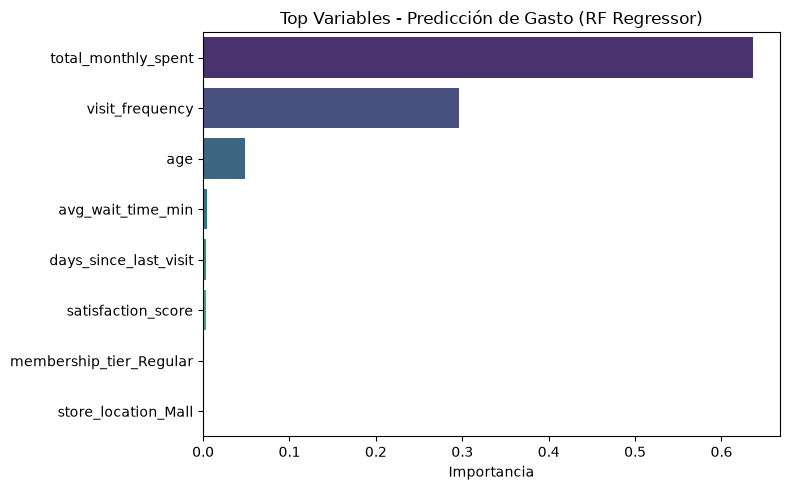

In [13]:
reg_importances = reg_pipeline.named_steps['regressor'].feature_importances_
df_reg_imp = pd.DataFrame({'Feature': encoded_features, 'Importance': reg_importances}).sort_values('Importance', ascending=False).head(8)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=df_reg_imp, hue='Feature', palette='viridis', legend=False)
plt.title('Top Variables - Predicción de Gasto (RF Regressor)')
plt.xlabel('Importancia')
plt.ylabel('')
plt.tight_layout()
plt.show()

## **Gráfico 2 Importancia Clasificación (Gradient Boosting)**

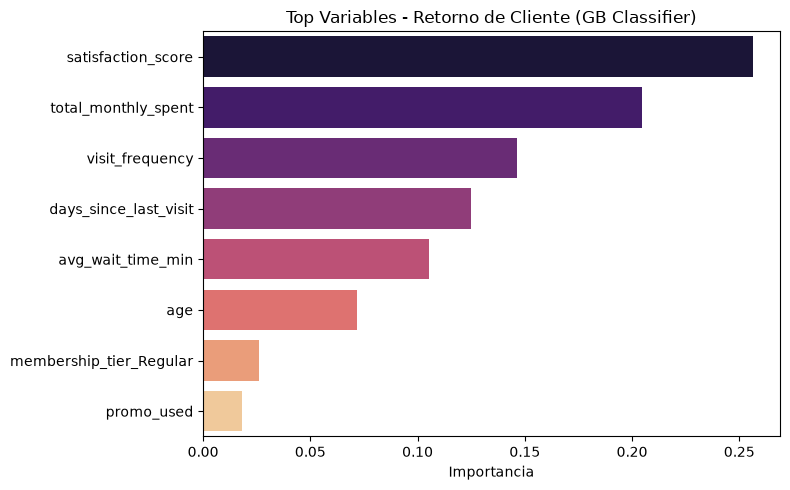

In [14]:
clf_importances = gb_clf_pipeline.named_steps['classifier'].feature_importances_
df_clf_imp = pd.DataFrame({'Feature': encoded_features, 'Importance': clf_importances}).sort_values('Importance', ascending=False).head(8)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=df_clf_imp, hue='Feature', palette='magma', legend=False)
plt.title('Top Variables - Retorno de Cliente (GB Classifier)')
plt.xlabel('Importancia')
plt.ylabel('')
plt.tight_layout()
plt.show()

## **Grafico 3: Matriz de Confusión Clasificación del Ganador (Gradient Boosting)**

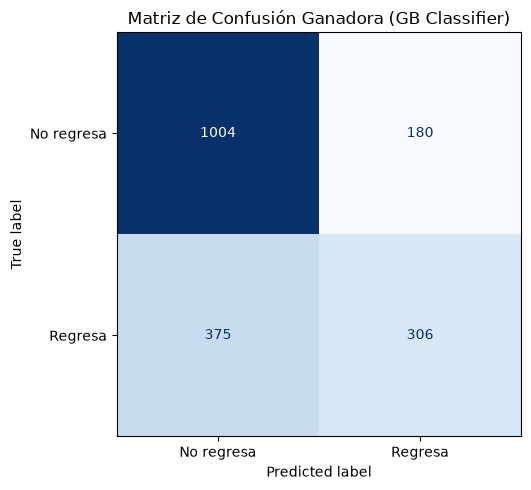

In [15]:
cm_gb = confusion_matrix(y_clf, y_clf_pred_gb)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=['No regresa', 'Regresa']).plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Matriz de Confusión Ganadora (GB Classifier)')
plt.tight_layout()
plt.show()

# **Storytelling**

## Hallazgo Técnico
¿Qué variables fueron más relevantes?

El análisis revela que variables financieras y de comportamiento recurrente como `total_monthly_spent` y `visit_frequency` son altamente predictivas para determinar tanto el gasto promedio de la visita actual como el potencial de recompra en la próxima semana.

Asimismo, `days_since_last_visit` resultó ser una variable importante para clasificar si un cliente volverá pronto.

## Interpretación de negocio
¿Qué aprendió CoffeeTime sobre sus clientes?

CoffeeTime Café ha aprendido que el comportamiento histórico de asistencia y gasto de sus clientes son el reflejo directo de su lealtad, por encima del nivel de membresía o de la ubicación del local. Los clientes que presentan un ciclo constante de visitas recientes son propensos a mantener un ticket alto y volver consistentemente la semana entrante, mientras que tiempos prolongados de ausencia disparan las probabilidades de abandono.

## Recomendación de mejora
¿Qué acciones podría tomar la gerencia?

1. **Campañas de Reactivación Automatizadas**: Diseñar ofertas e incentivos personalizados dirigidos a clientes que superen la media de días desde su última visita para evitar que se conviertan en baja definitiva.
2. **Incentivos de Frecuencia**: Implementar promociones de compras recurrentes o "visitas semanales consecutivas" (por ejemplo, acumulando sellos de lealtad en un período de 7 días) para motivar la consolidación de hábitos de consumo rápidos en locales clave.
3. **Upselling dirigido**: Aprovechar el perfil de los clientes con alto gasto mensual para sugerirles productos complementarios en su ticket diario mediante el personal o la app oficial.

# Modelo Preentrenado

In [16]:
import joblib
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

df = pd.read_csv("coffee_sales_clean.csv")

features = [
    "age",
    "visit_frequency",
    "coffee_type_preferred",
    "time_of_visit",
    "satisfaction_score",
    "total_monthly_spent",
    "store_location",
    "membership_tier",
    "promo_used",
    "avg_wait_time_min",
    "days_since_last_visit",
]

categorical_cols = [
    "coffee_type_preferred",
    "time_of_visit",
    "store_location",
    "membership_tier",
]
numerical_cols = [
    "age",
    "visit_frequency",
    "satisfaction_score",
    "total_monthly_spent",
    "promo_used",
    "avg_wait_time_min",
    "days_since_last_visit",
]


preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        (
            "cat",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_cols,
        ),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(n_estimators=100, random_state=42)),
    ]
)

# Training
X_clf = df[features]
y_clf = df["return_next_week"]
model.fit(X_clf, y_clf)

# Export
joblib.dump(model, "model.joblib", compress=3)
print("Modelo guardado correctamente en model.joblib")

Modelo guardado correctamente en model.joblib
